# Occupancy detection

**Author**: Fabio Colombo (fabio.colombo04@universitadipavia.it) - ID 580655.

Domotics offers a wide range of fascinating problems that machine learning tools can address. A notable example is occupancy detection: determining whether a room has people inside without relying on privacy-invasive sensors, such as video cameras.

A dataset has been collected for this purpose. It includes 8143 records reporting measures from sensors in a room. Each record includes the following information:
1. Temperature, in Celsius degrees;
2. Humidity, in percentage;
3. Light, in Lux;
4. CO2, in ppm;
5. Humidity ratio, calculated using the measured temperature and relative humidity;
6. Occupancy: indicating the presence or absence of people.

The last feature is binary, and is the one we want to predict, given the others. The dataset has already been divided into a training set of 6943 records, a validation set of 400 records, and a test set of 800 records. Each set is stored as a text file, with one record for each row, and with the features separated by spaces.

In [ ]:
# Drive mount
from google.colab import drive
drive.mount('/content/drive')

# Automatic zip search
import glob
import zipfile
import os

zip_matches = glob.glob('/content/drive/MyDrive/Machine_Learning_Project/Data/260831-occupancy.zip', recursive=True)

if not zip_matches:
    raise FileNotFoundError("File '260831-occupancy.zip' not found")

zip_path = zip_matches[0]
print("File zip in:", zip_path)

# Extraction
extract_dir = '/content/occupancy_data'
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

print("Extracted files:")
!ls -la {extract_dir}

Mounted at /content/drive
File zip in: /content/drive/MyDrive/Machine_Learning_Project/Data/260831-occupancy.zip
Extracted files:
total 368
drwxr-xr-x 2 root root   4096 Aug 24 13:14 .
drwxr-xr-x 1 root root   4096 Aug 24 13:14 ..
-rw-r--r-- 1 root root  35401 Aug 24 13:14 test.txt
-rw-r--r-- 1 root root 308552 Aug 24 13:14 train.txt
-rw-r--r-- 1 root root  17607 Aug 24 13:14 validation.txt


Data loaded and converted to tensors of features and class labels:

In [ ]:
import torch

def load_data(path):
    with open(path) as f:
        data = [float(x) for x in f.read().split()]
    data = torch.tensor(data).view(-1, 6)
    X = data[:, :5]
    Y = data[:, 5].long()
    return X, Y

X_train, Y_train = load_data(f"{extract_dir}/train.txt")
X_val, Y_val = load_data(f"{extract_dir}/validation.txt")
X_test, Y_test = load_data(f"{extract_dir}/test.txt")

print("Train:", X_train.shape, Y_train.shape)
print("Validation:", X_val.shape, Y_val.shape)
print("Test:", X_test.shape, Y_test.shape)

Train: torch.Size([6943, 5]) torch.Size([6943])
Validation: torch.Size([400, 5]) torch.Size([400])
Test: torch.Size([800, 5]) torch.Size([800])


## Dataset analysis (examined in depth in the report)

**Class balance.** The target is imbalanced across all three sets: roughly 80% of samples are labeled as "empty" (0) and 20% as "occupied" (1). This means a trivial classifier that always predicts "empty" would already score around 80% accuracy, so accuracy alone is not reliable — precision and recall needed.

**Feature ranges.** The features live on very different scales. Because of this, features are standardized before training.

**Correlation with the target.** Looking at correlation with Occupancy on the training set, Light and CO2 are by far the strongest predictors. This is consistent because lights tend to be on when someone is in the room, and CO2 accumulates with human presence.

**Data quality.** No missing values were found in any of the three files.

#### Class balance across the three sets


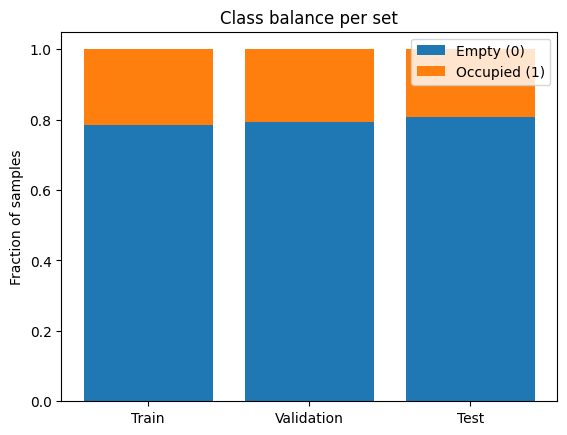

In [ ]:
import matplotlib.pyplot as plt

sets = ["Train", "Validation", "Test"]
Ys = [Y_train, Y_val, Y_test]

occupied = [y.float().mean().item() for y in Ys]
empty = [1 - o for o in occupied]

fig, ax = plt.subplots()
ax.bar(sets, empty, label="Empty (0)")
ax.bar(sets, occupied, bottom=empty, label="Occupied (1)")
ax.set_ylabel("Fraction of samples")
ax.set_title("Class balance per set")
ax.legend()
plt.show()

### Feature histograms split by class (train set)

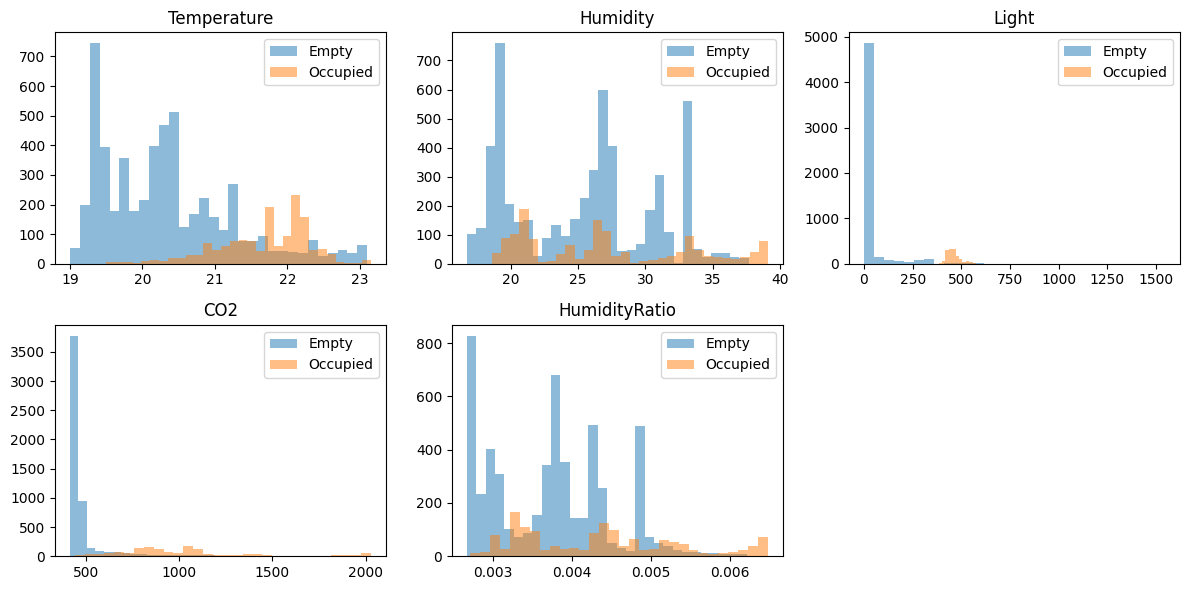

In [ ]:
features = ["Temperature", "Humidity", "Light", "CO2", "HumidityRatio"]

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
axes = axes.flatten()

for i, feat in enumerate(features):
    values_empty = X_train[Y_train == 0, i]
    values_occupied = X_train[Y_train == 1, i]

    axes[i].hist(values_empty.numpy(), bins=30, alpha=0.5, label="Empty")
    axes[i].hist(values_occupied.numpy(), bins=30, alpha=0.5, label="Occupied")
    axes[i].set_title(feat)
    axes[i].legend()

axes[-1].axis("off")
plt.tight_layout()
plt.show()

### Correlation with Occupancy

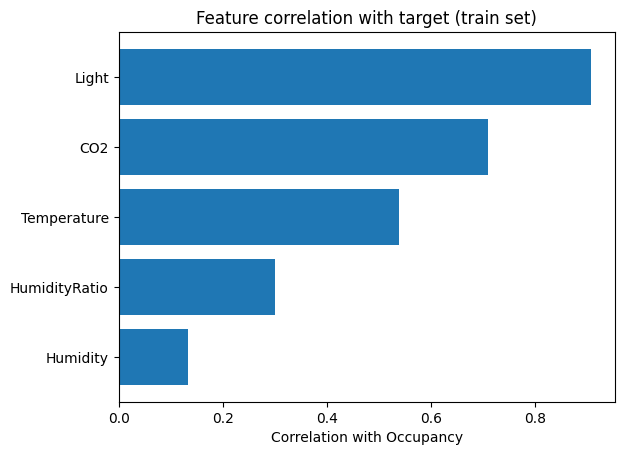

In [ ]:
Y_float = Y_train.float()

correlations = []
for i in range(X_train.shape[1]):
    x = X_train[:, i]
    x_centered = x - x.mean()
    y_centered = Y_float - Y_float.mean()
    corr = (x_centered * y_centered).sum() / (
        torch.sqrt((x_centered**2).sum()) * torch.sqrt((y_centered**2).sum())
    )
    correlations.append(corr.item())

# sort by value
sorted_pairs = sorted(zip(features, correlations), key=lambda p: p[1])
sorted_features = [p[0] for p in sorted_pairs]
sorted_corrs = [p[1] for p in sorted_pairs]

fig, ax = plt.subplots()
ax.barh(sorted_features, sorted_corrs)
ax.set_xlabel("Correlation with Occupancy")
ax.set_title("Feature correlation with target (train set)")
plt.show()

## Feature Standardization

Since the selected features operate on very different scales, applying feature
standardization is a necessary preprocessing step before training scale-sensitive models such as logistic regression optimized via gradient descent.

Without standardization, features with larger numeric ranges (e.g., CO2, Light) would dominate the gradient updates, while features with smaller ranges (e.g., HumidityRatio) would contribute negligibly, regardless of their actual predictive power.

We apply **Z-score standardization**, which rescales each feature to have zero mean and unit variance:

$$
x' = \frac{x - \mu}{\sigma}
$$

where:
- $x$ is the original feature value,
- $\mu$ is the mean of the feature computed on the **training set**,
- $\sigma$ is the standard deviation of the feature computed on the **training set**.

Importantly, $\mu$ and $\sigma$ are estimated **only on the training data** and then applied unchanged to the validation and test sets, in order to avoid data leakage.

In [ ]:
# STANDARDIZATION (z-score), fit only on train set

X_mean = X_train.mean(dim=0)
X_std = X_train.std(dim=0)

X_train = (X_train - X_mean) / X_std
X_val = (X_val - X_mean) / X_std
X_test = (X_test - X_mean) / X_std

print("Train mean after standardization:", X_train.mean(dim=0))
print("Train std after standardization:", X_train.std(dim=0))

Train mean after standardization: tensor([ 6.1701e-07, -2.4724e-08, -8.3788e-08, -1.8159e-07, -3.5988e-08])
Train std after standardization: tensor([1., 1., 1., 1., 1.])


## Models
Three different classification strategies are considered: Logistic Regression, Support Vector Machine and KNN. For each family we keep track of a **precision-oriented**, a **recall-oriented** and an **intermediate** (balanced) model.

All the metric/plotting functions reused across the four models are collected once in the *Utility functions* block right below, instead of being redefined inside each model's section.

### Utility functions

Before training the models, we collect here everything that is common to all of them: metric computation, threshold sweeping to build ROC / Precision-Recall curves, AUC computation, and selection of the three "operating points" (precision-oriented, recall-oriented, intermediate) for a given model.

Recall the standard definitions used throughout:

$$
\text{Precision} = \frac{TP}{TP+FP} \qquad \text{Recall} = \text{TPR} = \frac{TP}{TP+FN} \qquad \text{FPR} = \frac{FP}{FP+TN}
$$

$$
F_1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}
$$

The **ROC curve** plots TPR against FPR while the decision threshold is swept over the model's continuous scores; the **Precision-Recall curve** plots Precision against Recall over the same sweep. The area under the ROC curve is estimated with the trapezoidal rule:

$$
AUC \approx \sum_{i=1}^{n-1} \frac{(FPR_{i+1} - FPR_i)\,(TPR_{i+1} + TPR_i)}{2}
$$

For every model, the threshold is swept on the **validation set**, then we pick:
- the **precision-oriented** operating point: the highest precision among thresholds that still keep $\text{Recall} \geq 0.90$,
- the **recall-oriented** operating point: the highest recall among thresholds that still keep $\text{Precision} \geq 0.90$,
- the **intermediate** operating point: the threshold maximizing $F_1$ (unconstrained).

These thresholds are then applied, unchanged, to the **test set** to report final performance (avoiding any threshold selection leakage).

In [ ]:
# ============================================================
# COMMON UTILITY FUNCTIONS
# Shared across Logistic Regression, SVM and KNN
# ============================================================

def compute_metrics(predictions, Y):
    """Accuracy, precision and recall."""
    predictions = torch.as_tensor(predictions).long()
    Y = torch.as_tensor(Y).long()
    tp = ((predictions == 1) & (Y == 1)).sum().item()
    fp = ((predictions == 1) & (Y == 0)).sum().item()
    fn = ((predictions == 0) & (Y == 1)).sum().item()
    accuracy = (predictions == Y).float().mean().item()
    precision = tp / (tp + fp) if (tp + fp) > 0 else 1.0  # no positive predictions: precision undefined, convention = 1.0 (matches sklearn)
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    return accuracy, precision, recall


def compute_tpr_fpr(predictions, Y):
    """True Positive Rate and False Positive Rate."""
    predictions = torch.as_tensor(predictions).long()
    Y = torch.as_tensor(Y).long()
    tp = ((predictions == 1) & (Y == 1)).sum().item()
    fp = ((predictions == 1) & (Y == 0)).sum().item()
    tn = ((predictions == 0) & (Y == 0)).sum().item()
    fn = ((predictions == 0) & (Y == 1)).sum().item()
    tpr = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    return tpr, fpr


def compute_threshold_curves(scores, Y, thresholds=None):
    """
    Sweep decision thresholds over continuous scores and compute
    accuracy/precision/recall/TPR/FPR at each one.

    Default thresholds are derived from the data (midpoints between unique
    score values) and anchored with two boundary thresholds (everyone
    positive / everyone negative), so the curve always spans [0,1] and AUC
    is computed correctly regardless of the model's score scale.
    """
    scores = torch.as_tensor(scores).float()
    Y = torch.as_tensor(Y).long()

    if thresholds is None:
        unique_scores = torch.unique(scores, sorted=True)
        if unique_scores.numel() > 1:
            interior = (unique_scores[:-1] + unique_scores[1:]) / 2
        else:
            interior = unique_scores
        eps = 1e-6 * max(1.0, (unique_scores.max() - unique_scores.min()).item())
        lower_bound = (unique_scores.min() - eps).unsqueeze(0)
        upper_bound = (unique_scores.max() + eps).unsqueeze(0)
        thresholds = torch.cat([lower_bound, interior, upper_bound])

    accuracies, precisions, recalls, tprs, fprs = [], [], [], [], []
    for t in thresholds:
        predictions = (scores > t).long()
        accuracy, precision, recall = compute_metrics(predictions, Y)
        tpr, fpr = compute_tpr_fpr(predictions, Y)
        accuracies.append(accuracy)
        precisions.append(precision)
        recalls.append(recall)
        tprs.append(tpr)
        fprs.append(fpr)

    return {
        "thresholds": thresholds,
        "accuracy": torch.tensor(accuracies),
        "precision": torch.tensor(precisions),
        "recall": torch.tensor(recalls),
        "tpr": torch.tensor(tprs),
        "fpr": torch.tensor(fprs),
    }


def compute_auc(x, y):
    """
    Trapezoidal-rule area under the curve y(x). Returns the AUC.
    """
    x = torch.as_tensor(x).float()
    y = torch.as_tensor(y).float()
    order_y = torch.argsort(y, stable=True)
    x, y = x[order_y], y[order_y]
    order_x = torch.argsort(x, stable=True)
    x, y = x[order_x], y[order_x]
    return torch.trapz(y, x).item()


def plot_pr_curve(curves, title="Precision-Recall curve", ax=None):
    """Plot Precision vs Recall."""
    show = ax is None
    if ax is None:
        fig, ax = plt.subplots()
    ax.plot(curves["recall"], curves["precision"], marker='.')
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.set_title(title)
    ax.grid(True)
    if show:
        plt.show()


def plot_roc_curve(curves, title="ROC curve", ax=None):
    """Plot TPR vs FPR. Returns the AUC."""
    show = ax is None
    if ax is None:
        fig, ax = plt.subplots()
    auc = compute_auc(curves["fpr"], curves["tpr"])
    ax.plot(curves["fpr"], curves["tpr"], marker='.', label=f'ROC (AUC={auc:.3f})')
    ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(title)
    ax.legend()
    ax.grid(True)
    if show:
        plt.show()
    return auc


def select_threshold_models(curves, precision_constraint=0.90, recall_constraint=0.90):
    """
    Pick three operating points from a threshold sweep:
      - precision: best precision with recall >= recall_constraint
      - recall:    best recall with precision >= precision_constraint
      - intermediate: threshold maximizing F1 (unconstrained)
    Falls back to the unconstrained argmax if no threshold meets a constraint.
    """
    thresholds = curves["thresholds"]
    precisions = curves["precision"]
    recalls = curves["recall"]
    accuracies = curves["accuracy"]

    f1_scores = 2 * precisions * recalls / (precisions + recalls + 1e-8)

    def _pack(idx):
        return {
            "threshold": thresholds[idx].item(),
            "accuracy": accuracies[idx].item(),
            "precision": precisions[idx].item(),
            "recall": recalls[idx].item(),
        }

    recall_ok = recalls >= recall_constraint
    if recall_ok.any():
        idx_precision = torch.where(recall_ok, precisions, torch.full_like(precisions, -1.0)).argmax()
    else:
        print(f"  [note] no threshold reaches recall >= {recall_constraint}; falling back")
        idx_precision = torch.argmax(precisions)

    precision_ok = precisions >= precision_constraint
    if precision_ok.any():
        idx_recall = torch.where(precision_ok, recalls, torch.full_like(recalls, -1.0)).argmax()
    else:
        print(f"  [note] no threshold reaches precision >= {precision_constraint}; falling back")
        idx_recall = torch.argmax(recalls)

    idx_intermediate = torch.argmax(f1_scores)

    return {
        "precision": _pack(idx_precision),
        "recall": _pack(idx_recall),
        "intermediate": _pack(idx_intermediate),
    }


def print_operating_points(name, operating_points):
    """Print the three operating points."""
    print(f"--- {name}: operating points selected on the validation set ---")
    for kind in ["precision", "recall", "intermediate"]:
        op = operating_points[kind]
        print(f"  {kind:<12} threshold={op['threshold']:.2f}  "
              f"accuracy={op['accuracy']:.4f}  precision={op['precision']:.4f}  recall={op['recall']:.4f}")


def evaluate_operating_points_on_test(name, scores_test, Y_test, operating_points):
    """Apply the validation thresholds to the test set and report metrics."""
    scores_test = torch.as_tensor(scores_test).float()
    print(f"--- {name}: performance on the TEST set ---")
    results = {}
    for kind in ["precision", "recall", "intermediate"]:
        t = operating_points[kind]["threshold"]
        predictions = (scores_test > t).long()
        accuracy, precision, recall = compute_metrics(predictions, Y_test)
        results[kind] = {"threshold": t, "accuracy": accuracy, "precision": precision, "recall": recall}
        print(f"  {kind:<12} threshold={t:.2f}  accuracy={accuracy:.4f}  precision={precision:.4f}  recall={recall:.4f}")
    return results


def plot_confusion_matrix(predictions, Y, title="Confusion matrix", ax=None):
    """Plot a 2x2 confusion matrix."""
    predictions = torch.as_tensor(predictions).long()
    Y = torch.as_tensor(Y).long()
    tp = ((predictions == 1) & (Y == 1)).sum().item()
    tn = ((predictions == 0) & (Y == 0)).sum().item()
    fp = ((predictions == 1) & (Y == 0)).sum().item()
    fn = ((predictions == 0) & (Y == 1)).sum().item()
    cm = [[tn, fp], [fn, tp]]

    show = ax is None
    if ax is None:
        fig, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(cm, cmap='Blues')
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Pred 0', 'Pred 1'])
    ax.set_yticks([0, 1]); ax.set_yticklabels(['True 0', 'True 1'])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i][j], ha='center', va='center')
    ax.set_title(title, fontsize=10)
    if show:
        plt.tight_layout()
        plt.show()


def plot_operating_point_confusion_matrices(name, scores_test, Y_test, operating_points):
    """Plot the three operating-point confusion matrices side by side."""
    scores_test = torch.as_tensor(scores_test).float()
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax, kind in zip(axes, ["precision", "recall", "intermediate"]):
        t = operating_points[kind]["threshold"]
        predictions = (scores_test > t).long()
        plot_confusion_matrix(predictions, Y_test, title=f"{name}\n{kind} (t={t:.2f})", ax=ax)
    plt.tight_layout()
    plt.show()


### 1. Logistic Regression

In [ ]:
# INFERENCE FUNCTION
# we want the prediction for each element of X
def logreg_inference(w, b, X):
    logits = X @ w + b
    p = torch.sigmoid(logits) # better for automatic differentiation
    return p

In [ ]:
# TRAINING LOOP
def logreg_train(X, Y, lr=0.005, steps=20000, log_every=500):
    n = X.shape[1]
    w = torch.zeros(n, requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    loss_fun = torch.nn.BCELoss()
    optimizer = torch.optim.SGD([w, b], lr=lr)

    steps_list, losses_list, accuracies_list = [], [], []

    for step in range(steps):
        optimizer.zero_grad()
        p = logreg_inference(w, b, X)
        loss = loss_fun(p, Y.float())
        loss.backward()
        optimizer.step()

        if step % log_every == 0:
            steps_list.append(step)
            losses_list.append(loss.item())
            predictions = (p > 0.5).long()
            accuracy = (predictions == Y).float().mean().item()
            accuracies_list.append(accuracy)
            print(f"Step {step}: loss={loss.item():.4f} accuracy={accuracy:.4f}")

    return w, b, steps_list, losses_list, accuracies_list

In [ ]:
w, b, steps, losses, accuracies = logreg_train(X_train, Y_train, lr=0.005, steps=20000)

Step 0: loss=0.6931 accuracy=0.7853
Step 500: loss=0.3169 accuracy=0.9473
Step 1000: loss=0.2257 accuracy=0.9538
Step 1500: loss=0.1837 accuracy=0.9623
Step 2000: loss=0.1591 accuracy=0.9670
Step 2500: loss=0.1428 accuracy=0.9729
Step 3000: loss=0.1311 accuracy=0.9775
Step 3500: loss=0.1223 accuracy=0.9813
Step 4000: loss=0.1153 accuracy=0.9836
Step 4500: loss=0.1098 accuracy=0.9849
Step 5000: loss=0.1052 accuracy=0.9852
Step 5500: loss=0.1013 accuracy=0.9855
Step 6000: loss=0.0980 accuracy=0.9857
Step 6500: loss=0.0952 accuracy=0.9863
Step 7000: loss=0.0927 accuracy=0.9867
Step 7500: loss=0.0906 accuracy=0.9870
Step 8000: loss=0.0886 accuracy=0.9875
Step 8500: loss=0.0869 accuracy=0.9876
Step 9000: loss=0.0854 accuracy=0.9878
Step 9500: loss=0.0840 accuracy=0.9878
Step 10000: loss=0.0827 accuracy=0.9878
Step 10500: loss=0.0816 accuracy=0.9878
Step 11000: loss=0.0806 accuracy=0.9878
Step 11500: loss=0.0796 accuracy=0.9878
Step 12000: loss=0.0787 accuracy=0.9878
Step 12500: loss=0.0779 

Text(0, 0.5, 'Accuracies')

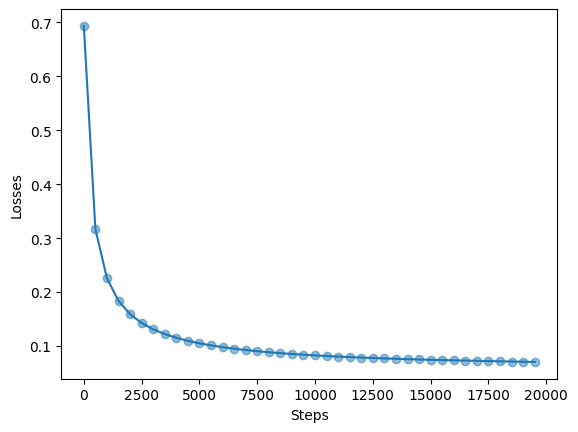

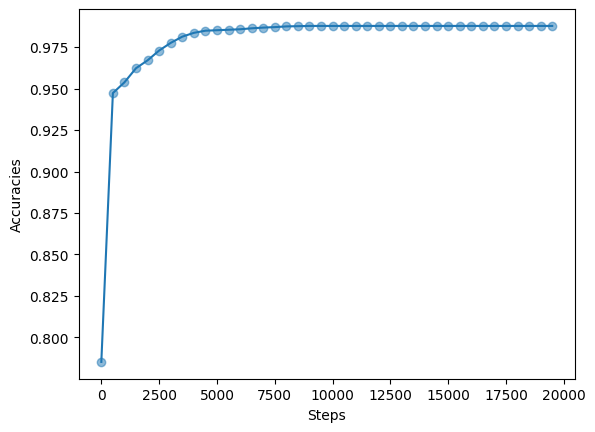

In [ ]:
plt.figure()
plt.plot(steps, losses)

plt.scatter(steps, losses, alpha=0.5)
plt.xlabel('Steps')
plt.ylabel('Losses')

plt.figure()
plt.plot(steps, accuracies)

plt.scatter(steps, accuracies, alpha=0.5)
plt.xlabel('Steps')
plt.ylabel('Accuracies')

#### Grid search: L1 vs L2 regularization

In [ ]:
# GRID SEARCH - L1 and L2 regularization (with precision/recall)

lambda_values = [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.05, 0.1, 0.3, 0.5, 1.0]

LR = 0.005
STEPS = 10000

# compute_metrics is defined once in the \"Utility functions\" block above.

results_L1 = []
results_L2 = []

# --- L1 regularization ---
for lambda_ in lambda_values:
    w = torch.zeros(5, requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    optimizer = torch.optim.SGD([w, b], lr=LR)
    loss_fun = torch.nn.BCELoss()

    for step in range(STEPS):
        optimizer.zero_grad()
        p = logreg_inference(w, b, X_train)
        l1_norm = torch.sum(torch.abs(w))
        loss = loss_fun(p, Y_train.float()) + lambda_ * l1_norm
        loss.backward()
        optimizer.step()

    p_val = logreg_inference(w, b, X_val)
    predictions_val = (p_val > 0.5).long()
    accuracy_val, precision_val, recall_val = compute_metrics(predictions_val, Y_val)

    results_L1.append((lambda_, accuracy_val, precision_val, recall_val, w.detach().clone(), b.detach().clone()))
    print(f"L1 - lambda={lambda_:<8} acc={accuracy_val:.4f} precision={precision_val:.4f} recall={recall_val:.4f}")

print()

# --- L2 regularization ---
for lambda_ in lambda_values:
    w = torch.zeros(5, requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    optimizer = torch.optim.SGD([
    {'params': [w], 'weight_decay': lambda_},
    {'params': [b], 'weight_decay': 0.0}
], lr=LR)
    loss_fun = torch.nn.BCELoss()

    for step in range(STEPS):
        optimizer.zero_grad()
        p = logreg_inference(w, b, X_train)
        loss = loss_fun(p, Y_train.float())
        loss.backward()
        optimizer.step()

    p_val = logreg_inference(w, b, X_val)
    predictions_val = (p_val > 0.5).long()
    accuracy_val, precision_val, recall_val = compute_metrics(predictions_val, Y_val)

    results_L2.append((lambda_, accuracy_val, precision_val, recall_val, w.detach().clone(), b.detach().clone()))
    print(f"L2 - lambda={lambda_:<8} acc={accuracy_val:.4f} precision={precision_val:.4f} recall={recall_val:.4f}")

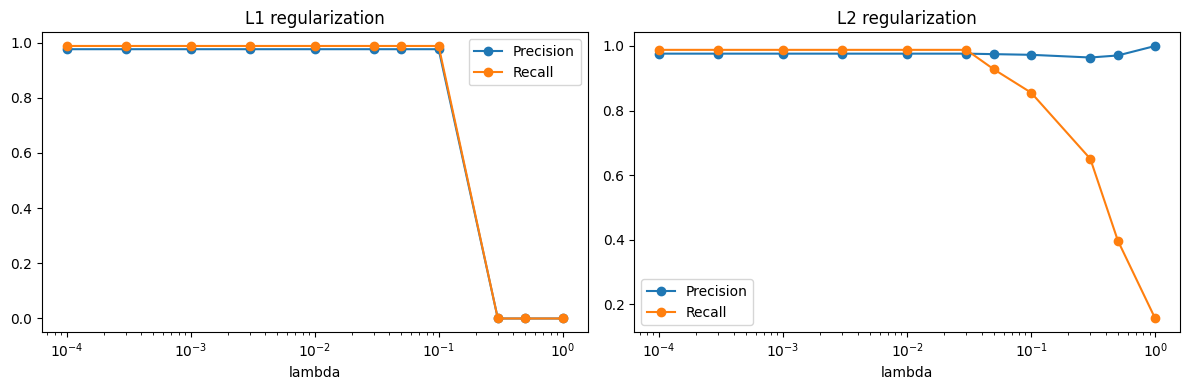

In [ ]:
import matplotlib.pyplot as plt

lambdas_L1 = [r[0] for r in results_L1]
prec_L1 = [r[2] for r in results_L1]
rec_L1 = [r[3] for r in results_L1]

lambdas_L2 = [r[0] for r in results_L2]
prec_L2 = [r[2] for r in results_L2]
rec_L2 = [r[3] for r in results_L2]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(lambdas_L1, prec_L1, marker='o', label='Precision')
axes[0].plot(lambdas_L1, rec_L1, marker='o', label='Recall')
axes[0].set_xscale('log')
axes[0].set_xlabel('lambda')
axes[0].set_title('L1 regularization')
axes[0].legend()

axes[1].plot(lambdas_L2, prec_L2, marker='o', label='Precision')
axes[1].plot(lambdas_L2, rec_L2, marker='o', label='Recall')
axes[1].set_xscale('log')
axes[1].set_xlabel('lambda')
axes[1].set_title('L2 regularization')
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
all_results = results_L1 + results_L2

best_precision_model = max(all_results, key=lambda r: r[2])
best_recall_model = max(all_results, key=lambda r: r[3])
best_accuracy_model = max(all_results, key=lambda r: r[1])

print("Precision-oriented model:")
print(f"  lambda={best_precision_model[0]}, accuracy={best_precision_model[1]:.4f}, "
      f"precision={best_precision_model[2]:.4f}, recall={best_precision_model[3]:.4f}")

print("\nRecall-oriented model:")
print(f"  lambda={best_recall_model[0]}, accuracy={best_recall_model[1]:.4f}, "
      f"precision={best_recall_model[2]:.4f}, recall={best_recall_model[3]:.4f}")

print("\nIntermediate (best accuracy) model:")
print(f"  lambda={best_accuracy_model[0]}, accuracy={best_accuracy_model[1]:.4f}, "
      f"precision={best_accuracy_model[2]:.4f}, recall={best_accuracy_model[3]:.4f}")

Precision-oriented model:
  lambda=1.0, accuracy=0.8250, precision=1.0000, recall=0.1566

Recall-oriented model:
  lambda=0.0001, accuracy=0.9925, precision=0.9762, recall=0.9880

Intermediate (best accuracy) model:
  lambda=0.0001, accuracy=0.9925, precision=0.9762, recall=0.9880


#### ROC / Precision-Recall curves and operating points (validation set) — Logistic Regression

In [ ]:
# Train the final model with an intermediate lambda (best accuracy model)
lambda_final = best_accuracy_model[0]

w = torch.zeros(5, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
optimizer = torch.optim.SGD([w, b], lr=LR, weight_decay=lambda_final)
loss_fun = torch.nn.BCELoss()

for step in range(STEPS):
    optimizer.zero_grad()
    p = logreg_inference(w, b, X_train)
    loss = loss_fun(p, Y_train.float())
    loss.backward()
    optimizer.step()

# Compute probability scores on the validation set (not the 0/1 predictions)
p_val = logreg_inference(w, b, X_val).detach()

In [ ]:
# Sweep the decision threshold on the validation set and collect Precision/Recall/TPR/FPR
curves_logreg = compute_threshold_curves(p_val, Y_val)

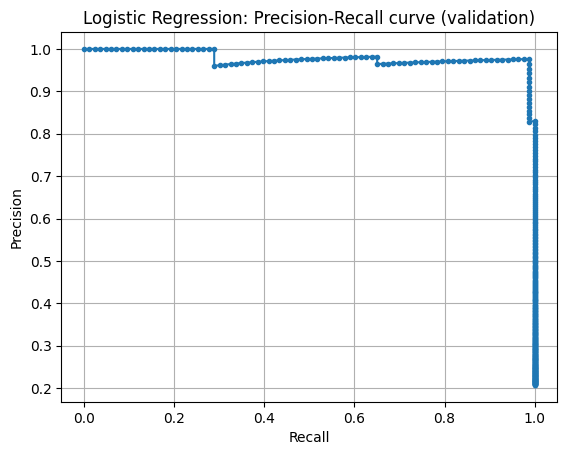

In [ ]:
plot_pr_curve(curves_logreg, title='Logistic Regression: Precision-Recall curve (validation)')

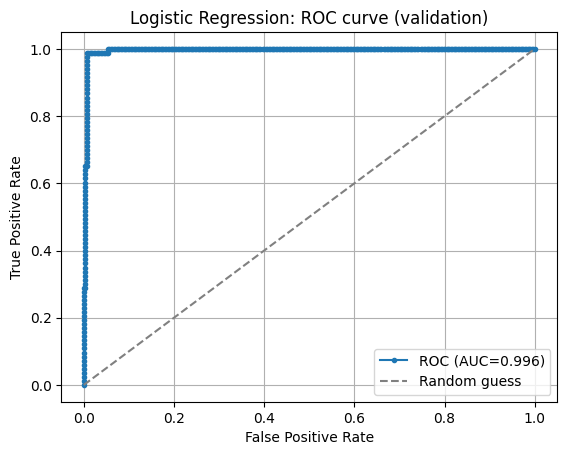

AUC = 0.9961


In [ ]:
auc_logreg = plot_roc_curve(curves_logreg, title='Logistic Regression: ROC curve (validation)')
print(f'AUC = {auc_logreg:.4f}')

In [ ]:
op_logreg = select_threshold_models(curves_logreg)
print_operating_points('Logistic Regression', op_logreg)

--- Logistic Regression: operating points selected on the validation set ---
  precision    threshold=0.52  accuracy=0.9925  precision=0.9762  recall=0.9880
  recall       threshold=0.30  accuracy=0.9750  precision=0.9011  recall=0.9880
  intermediate threshold=0.52  accuracy=0.9925  precision=0.9762  recall=0.9880


### 2. Support Vector Machine

#### Linear SVM

In [ ]:
# LINEAR SVM

def hinge_loss(z, y):
    y_pm1 = 2*y.float() - 1  # map {0,1} -> {-1,+1}
    return torch.clamp(1 - y_pm1*z, min=0).mean()

def svm_train(X,Y,lambda_, lr=1e-3, steps=10000):
  m,n = X.shape
  w = torch.zeros(n, requires_grad=True)
  b = torch.zeros(1, requires_grad=True)
  optimizer = torch.optim.SGD([w,b], lr=lr, weight_decay=lambda_)
  for step in range(steps):
    optimizer.zero_grad()
    z = X @ w + b
    loss = hinge_loss(z,Y)
    loss.backward()
    optimizer.step()
  return w,b

In [ ]:
def svm_inference(w,b,X):
  z = X @ w + b
  p = torch.sigmoid(z)
  return p

##### Hyperparameter search: regularization strength (λ)

The linear SVM is trained with `weight_decay=lambda_` in the optimizer, which adds an $L_2$ penalty $\frac{\lambda}{2}\lVert w \rVert^2$ to the hinge-loss objective — the standard soft-margin SVM formulation. We sweep λ on a log-spaced grid, train on the training set and evaluate on the validation set, then keep the model with the best validation accuracy.

In [ ]:
# HYPERPARAMETER SEARCH - Linear SVM (regularization strength)

lambda_values_svm = [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]
STEPS_SVM = 10000

results_svm_search = []

for lambda_ in lambda_values_svm:
    w_svm, b_svm = svm_train(X_train, Y_train, lambda_=lambda_, lr=1e-3, steps=STEPS_SVM)

    p_val_search = svm_inference(w_svm, b_svm, X_val).detach()
    predictions_val = (p_val_search > 0.5).long()
    accuracy_val, precision_val, recall_val = compute_metrics(predictions_val, Y_val)

    results_svm_search.append((lambda_, accuracy_val, precision_val, recall_val, w_svm.detach().clone(), b_svm.detach().clone()))
    print(f"Linear SVM - lambda={lambda_:<8} acc={accuracy_val:.4f} precision={precision_val:.4f} recall={recall_val:.4f}")

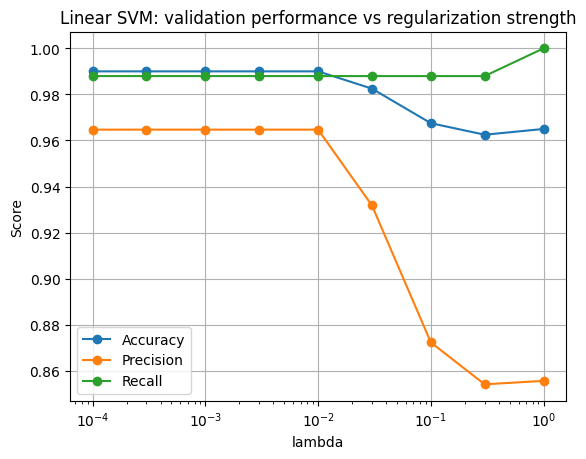

In [ ]:
lambdas_svm = [r[0] for r in results_svm_search]
acc_svm_search = [r[1] for r in results_svm_search]
prec_svm_search = [r[2] for r in results_svm_search]
rec_svm_search = [r[3] for r in results_svm_search]

plt.figure()
plt.plot(lambdas_svm, acc_svm_search, marker='o', label='Accuracy')
plt.plot(lambdas_svm, prec_svm_search, marker='o', label='Precision')
plt.plot(lambdas_svm, rec_svm_search, marker='o', label='Recall')
plt.xscale('log')
plt.xlabel('lambda')
plt.ylabel('Score')
plt.title('Linear SVM: validation performance vs regularization strength')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Select the configuration with the best validation accuracy
best_svm_result = max(results_svm_search, key=lambda r: r[1])
best_lambda_svm = best_svm_result[0]
w_svm, b_svm = best_svm_result[4], best_svm_result[5]

print(f"Best Linear SVM configuration: lambda={best_lambda_svm}")
print(f"  accuracy={best_svm_result[1]:.4f}  precision={best_svm_result[2]:.4f}  recall={best_svm_result[3]:.4f}  (validation)")

#### ROC / Precision-Recall curves and operating points (validation set) — Linear SVM

In [ ]:
p_val_svm = svm_inference(w_svm, b_svm, X_val).detach()
curves_svm_linear = compute_threshold_curves(p_val_svm, Y_val)

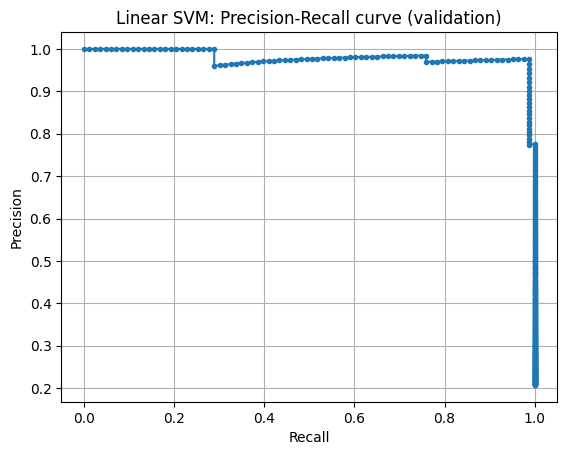

In [ ]:
plot_pr_curve(curves_svm_linear, title='Linear SVM: Precision-Recall curve (validation)')

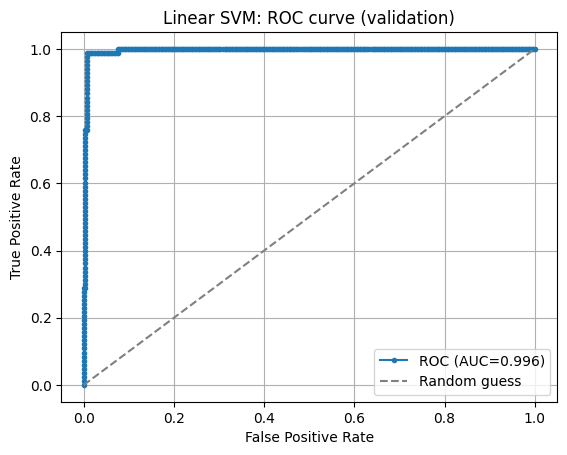

AUC = 0.9962


In [ ]:
auc_svm_linear = plot_roc_curve(curves_svm_linear, title='Linear SVM: ROC curve (validation)')
print(f'AUC = {auc_svm_linear:.4f}')

In [ ]:
op_svm_linear = select_threshold_models(curves_svm_linear)
print_operating_points('Linear SVM', op_svm_linear)

--- Linear SVM: operating points selected on the validation set ---
  precision    threshold=0.62  accuracy=0.9925  precision=0.9762  recall=0.9880
  recall       threshold=0.44  accuracy=0.9750  precision=0.9011  recall=0.9880
  intermediate threshold=0.62  accuracy=0.9925  precision=0.9762  recall=0.9880


### 3. K-Nearest Neighbors

KNN k=1   acc=0.9925 precision=1.0000 recall=0.9639
KNN k=3   acc=0.9950 precision=1.0000 recall=0.9759
KNN k=5   acc=0.9950 precision=1.0000 recall=0.9759
KNN k=10  acc=0.9950 precision=1.0000 recall=0.9759
KNN k=15  acc=0.9950 precision=1.0000 recall=0.9759
KNN k=20  acc=0.9975 precision=1.0000 recall=0.9880


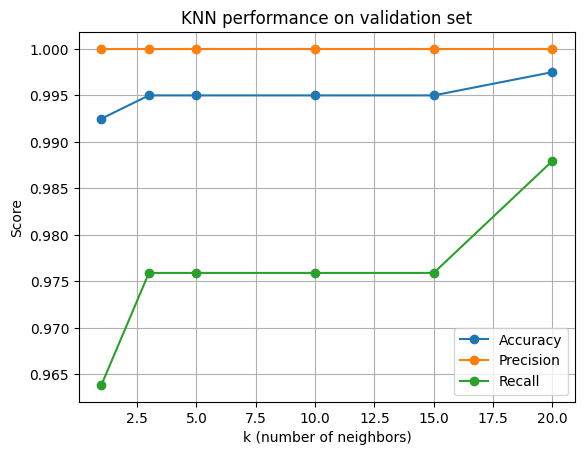

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt

k_values = [1, 3, 5, 10, 15, 20]

acc_list, prec_list, rec_list = [], [], []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, Y_train)
    predictions_val = knn.predict(X_val)
    accuracy, precision, recall = compute_metrics(torch.tensor(predictions_val), Y_val)
    acc_list.append(accuracy)
    prec_list.append(precision)
    rec_list.append(recall)
    print(f"KNN k={k:<3} acc={accuracy:.4f} precision={precision:.4f} recall={recall:.4f}")

plt.figure()
plt.plot(k_values, acc_list, marker='o', label='Accuracy')
plt.plot(k_values, prec_list, marker='o', label='Precision')
plt.plot(k_values, rec_list, marker='o', label='Recall')
plt.xlabel('k (number of neighbors)')
plt.ylabel('Score')
plt.title('KNN performance on validation set')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# k selected by me
best_k_idx = acc_list.index(max(acc_list))
best_k = k_values[best_k_idx]
print(f"Best k selected on validation: 5")

# retrain with k and evaluate on the test set
knn_best = KNeighborsClassifier(n_neighbors=5)
knn_best.fit(X_train, Y_train)

predictions_test = knn_best.predict(X_test)
accuracy_test, precision_test, recall_test = compute_metrics(torch.tensor(predictions_test), Y_test)

print(f"KNN (k=5) - TEST SET  acc={accuracy_test:.4f} precision={precision_test:.4f} recall={recall_test:.4f}")

Best k selected on validation: 5
KNN (k=5) - TEST SET  acc=0.9912 precision=0.9744 recall=0.9806


#### ROC / Precision-Recall curves and operating points (validation set) — KNN

*Note: `predict_proba` for KNN with k=5 can only return 6 distinct probability values (0, 1/5, ..., 5/5 — the fraction of the k neighbors in each class), so the curves below have only a handful of points connected by straight segments instead of a smooth curve. This is an expected property of KNN as a probability estimator, not a plotting error, and is discussed as such in the report.*

In [ ]:
# KNN exposes predict_proba: we use P(occupied) as the continuous score for threshold sweeping
p_val_knn = torch.tensor(knn_best.predict_proba(X_val)[:, 1]).float()
curves_knn = compute_threshold_curves(p_val_knn, Y_val)

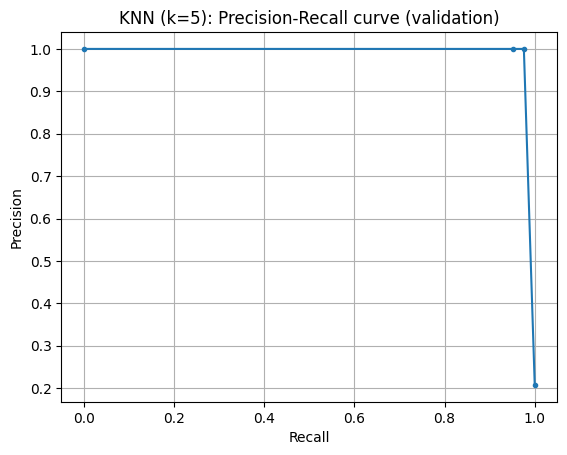

In [ ]:
plot_pr_curve(curves_knn, title='KNN (k=5): Precision-Recall curve (validation)')

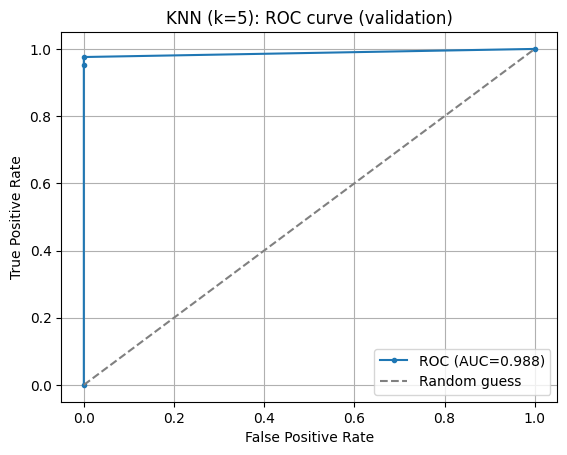

AUC = 0.9880


In [ ]:
auc_knn = plot_roc_curve(curves_knn, title='KNN (k=5): ROC curve (validation)')
print(f'AUC = {auc_knn:.4f}')

In [ ]:
op_knn = select_threshold_models(curves_knn)
print_operating_points('KNN (k=5)', op_knn)

--- KNN (k=5): operating points selected on the validation set ---
  precision    threshold=0.40  accuracy=0.9950  precision=1.0000  recall=0.9759
  recall       threshold=0.40  accuracy=0.9950  precision=1.0000  recall=0.9759
  intermediate threshold=0.40  accuracy=0.9950  precision=1.0000  recall=0.9759


### 4. Multi-Layer Perceptron (MLP)

As a fourth model we consider a small feed-forward neural network with two hidden layers and ReLU activations: $5 \to 16 \to 8 \to 1$. Given how strongly Light and CO2 already correlate with Occupancy (see the dataset analysis above), and how well the simpler models already perform, the MLP is mainly a way to check whether a non-linear model can meaningfully improve on them, rather than something we expect to be strictly necessary.

The network outputs raw logits (no final sigmoid) and is trained with `BCEWithLogitsLoss`, which combines the sigmoid and the binary cross-entropy in a single numerically-stable operation — this avoids the sigmoid-saturation issues we ran into earlier with the kernel SVM's unbounded margins.

In [ ]:
# MLP MODEL AND TRAINING LOOP

class MLP(torch.nn.Module):
    def __init__(self, input_dim=5, hidden1=16, hidden2=8):
        super().__init__()
        self.net = torch.nn.Sequential(
            torch.nn.Linear(input_dim, hidden1),
            torch.nn.ReLU(),
            torch.nn.Linear(hidden1, hidden2),
            torch.nn.ReLU(),
            torch.nn.Linear(hidden2, 1),
        )

    def forward(self, X):
        return self.net(X).squeeze(-1)  # raw logits


def mlp_train(X, Y, hidden1=16, hidden2=8, lr=0.01, weight_decay=0.0, steps=5000, log_every=500, verbose=True):
    model = MLP(input_dim=X.shape[1], hidden1=hidden1, hidden2=hidden2)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fun = torch.nn.BCEWithLogitsLoss()

    steps_list, losses_list, accuracies_list = [], [], []
    for step in range(steps):
        optimizer.zero_grad()
        logits = model(X)
        loss = loss_fun(logits, Y.float())
        loss.backward()
        optimizer.step()

        if step % log_every == 0:
            steps_list.append(step)
            losses_list.append(loss.item())
            predictions = (logits > 0).long()  # logit > 0  <=>  sigmoid(logit) > 0.5
            accuracy = (predictions == Y).float().mean().item()
            accuracies_list.append(accuracy)
            if verbose:
                print(f"Step {step}: loss={loss.item():.4f} accuracy={accuracy:.4f}")

    return model, steps_list, losses_list, accuracies_list


def mlp_inference(model, X):
    """Returns sigmoid probabilities (continuous scores in [0,1])."""
    model.eval()
    with torch.no_grad():
        p = torch.sigmoid(model(X))
    model.train()
    return p

#### Hyperparameter search: regularization strength (weight decay)

Keeping the architecture fixed ($16 \to 8$ hidden units), we sweep the $L_2$ weight decay used by Adam, the same regularization idea used for the linear models, and keep the configuration with the best validation accuracy.

In [ ]:
# HYPERPARAMETER SEARCH - MLP (weight decay)

weight_decay_values_mlp = [0.0, 1e-4, 1e-3, 1e-2, 1e-1]
STEPS_MLP = 5000

results_mlp_search = []

for wd in weight_decay_values_mlp:
    model_search, _, _, _ = mlp_train(X_train, Y_train, lr=0.01, weight_decay=wd, steps=STEPS_MLP, verbose=False)

    p_val_search = mlp_inference(model_search, X_val)
    predictions_val = (p_val_search > 0.5).long()
    accuracy_val, precision_val, recall_val = compute_metrics(predictions_val, Y_val)

    results_mlp_search.append((wd, accuracy_val, precision_val, recall_val, model_search))
    print(f"MLP - weight_decay={wd:<8} acc={accuracy_val:.4f} precision={precision_val:.4f} recall={recall_val:.4f}")

In [ ]:
wd_values = [r[0] for r in results_mlp_search]
acc_mlp_search = [r[1] for r in results_mlp_search]
prec_mlp_search = [r[2] for r in results_mlp_search]
rec_mlp_search = [r[3] for r in results_mlp_search]

plt.figure()
plt.plot(range(len(wd_values)), acc_mlp_search, marker='o', label='Accuracy')
plt.plot(range(len(wd_values)), prec_mlp_search, marker='o', label='Precision')
plt.plot(range(len(wd_values)), rec_mlp_search, marker='o', label='Recall')
plt.xticks(range(len(wd_values)), [str(wd) for wd in wd_values])
plt.xlabel('weight decay')
plt.ylabel('Score')
plt.title('MLP: validation performance vs weight decay')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Select the configuration with the best validation accuracy
best_mlp_result = max(results_mlp_search, key=lambda r: r[1])
best_weight_decay_mlp = best_mlp_result[0]
mlp_model = best_mlp_result[4]

print(f"Best MLP configuration: weight_decay={best_weight_decay_mlp}")
print(f"  accuracy={best_mlp_result[1]:.4f}  precision={best_mlp_result[2]:.4f}  recall={best_mlp_result[3]:.4f}  (validation)")

#### ROC / Precision-Recall curves and operating points (validation set) — MLP

In [ ]:
p_val_mlp = mlp_inference(mlp_model, X_val)
curves_mlp = compute_threshold_curves(p_val_mlp, Y_val)

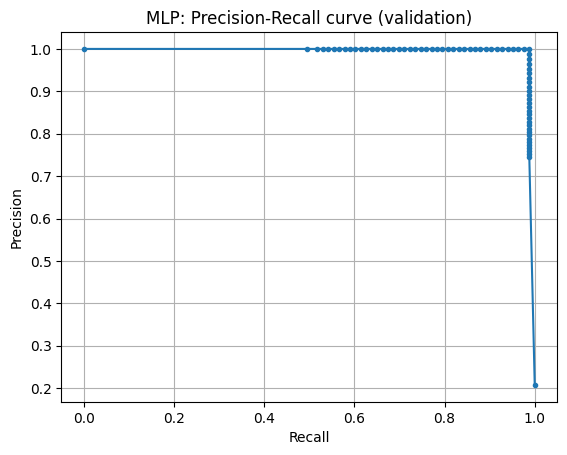

In [ ]:
plot_pr_curve(curves_mlp, title='MLP: Precision-Recall curve (validation)')

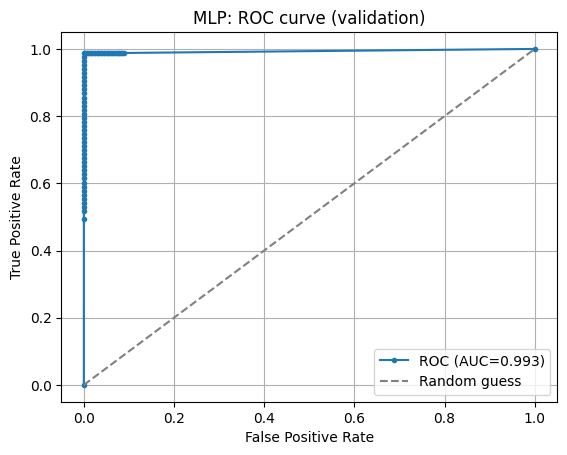

AUC = 0.9934


In [ ]:
auc_mlp = plot_roc_curve(curves_mlp, title='MLP: ROC curve (validation)')
print(f'AUC = {auc_mlp:.4f}')

In [ ]:
op_mlp = select_threshold_models(curves_mlp)
print_operating_points('MLP', op_mlp)

--- MLP: operating points selected on the validation set ---
  precision    threshold=0.52  accuracy=0.9975  precision=1.0000  recall=0.9880
  recall       threshold=0.00  accuracy=0.9750  precision=0.9011  recall=0.9880
  intermediate threshold=0.52  accuracy=0.9975  precision=1.0000  recall=0.9880


## Test set evaluation

For every model, the three operating points (precision-oriented, recall-oriented, intermediate) selected on the validation set are now applied — unchanged — to the test set. For each model we report the metrics at all three operating points together with their confusion matrices.

### Logistic Regression — test set

In [ ]:
p_test_logreg = logreg_inference(w, b, X_test).detach()
results_logreg_test = evaluate_operating_points_on_test('Logistic Regression', p_test_logreg, Y_test, op_logreg)

--- Logistic Regression: performance on the TEST set ---
  precision    threshold=0.52  accuracy=0.9912  precision=0.9568  recall=1.0000
  recall       threshold=0.30  accuracy=0.9787  precision=0.9012  recall=1.0000
  intermediate threshold=0.52  accuracy=0.9912  precision=0.9568  recall=1.0000


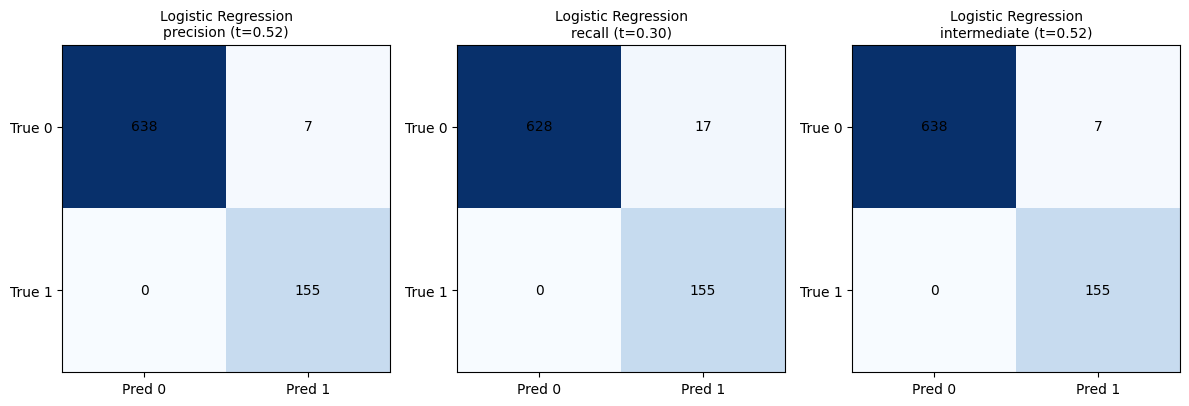

In [ ]:
plot_operating_point_confusion_matrices('Logistic Regression', p_test_logreg, Y_test, op_logreg)

### Linear SVM — test set

In [ ]:
p_test_svm = svm_inference(w_svm, b_svm, X_test).detach()
results_svm_linear_test = evaluate_operating_points_on_test('Linear SVM', p_test_svm, Y_test, op_svm_linear)

--- Linear SVM: performance on the TEST set ---
  precision    threshold=0.62  accuracy=0.9875  precision=0.9560  recall=0.9806
  recall       threshold=0.44  accuracy=0.9750  precision=0.8857  recall=1.0000
  intermediate threshold=0.62  accuracy=0.9875  precision=0.9560  recall=0.9806


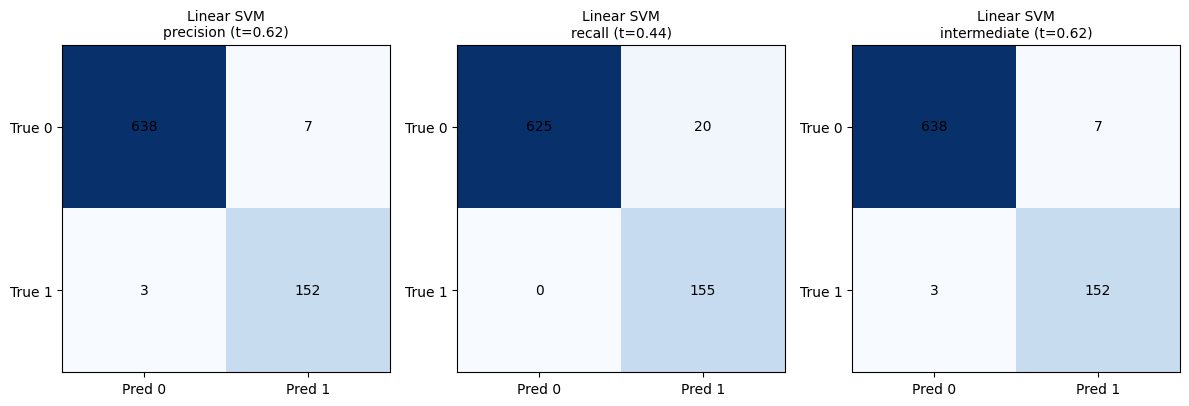

In [ ]:
plot_operating_point_confusion_matrices('Linear SVM', p_test_svm, Y_test, op_svm_linear)

### KNN — test set

In [ ]:
p_test_knn = torch.tensor(knn_best.predict_proba(X_test)[:, 1]).float()
results_knn_test = evaluate_operating_points_on_test('KNN (k=5)', p_test_knn, Y_test, op_knn)

--- KNN (k=5): performance on the TEST set ---
  precision    threshold=0.40  accuracy=0.9912  precision=0.9744  recall=0.9806
  recall       threshold=0.40  accuracy=0.9912  precision=0.9744  recall=0.9806
  intermediate threshold=0.40  accuracy=0.9912  precision=0.9744  recall=0.9806


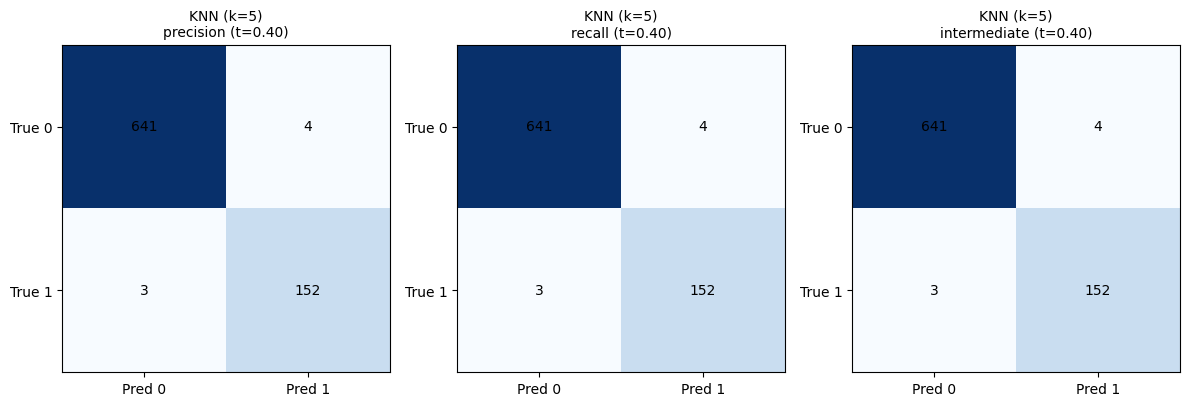

In [ ]:
plot_operating_point_confusion_matrices('KNN (k=5)', p_test_knn, Y_test, op_knn)

### MLP — test set

In [ ]:
p_test_mlp = mlp_inference(mlp_model, X_test)
results_mlp_test = evaluate_operating_points_on_test('MLP', p_test_mlp, Y_test, op_mlp)

--- MLP: performance on the TEST set ---
  precision    threshold=0.52  accuracy=0.9925  precision=0.9806  recall=0.9806
  recall       threshold=0.00  accuracy=0.9800  precision=0.9064  recall=1.0000
  intermediate threshold=0.52  accuracy=0.9925  precision=0.9806  recall=0.9806


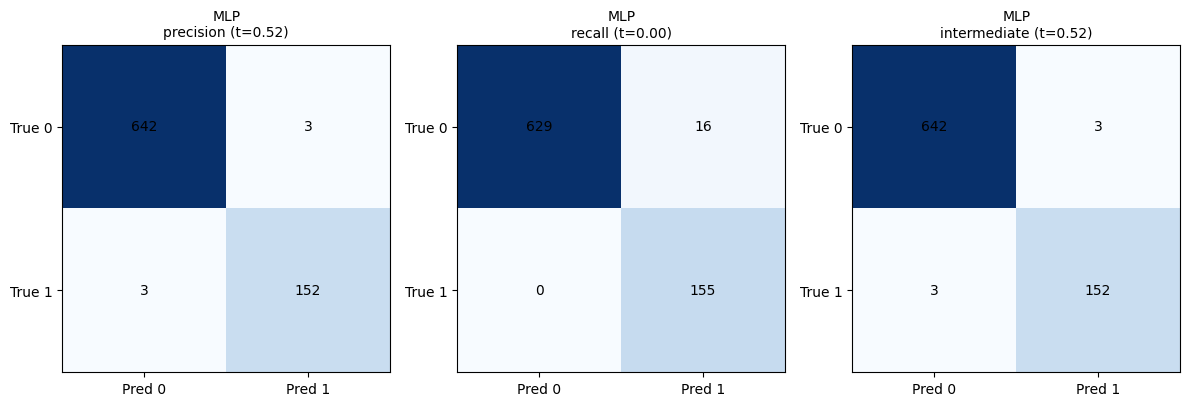

In [ ]:
plot_operating_point_confusion_matrices('MLP', p_test_mlp, Y_test, op_mlp)

## Summary: comparison across models

The table below collects, for every model family, the three operating points (precision-oriented, recall-oriented, intermediate) selected on the validation set and evaluated on the test set.

The table is also visible in the final section of the activity report.
TABLE REMOVED FROM THE OUTPUT BECAUSE NOT VISIBLE DURING THE PRINT OF THE NOTEBOOK IN PDF FORMAT.

In [ ]:
import pandas as pd

all_results = {
    "Logistic Regression": results_logreg_test,
    "Linear SVM": results_svm_linear_test,
    "KNN (k=5)": results_knn_test,
    "MLP": results_mlp_test,
}

rows = []
for model_name, res in all_results.items():
    for kind in ["precision", "recall", "intermediate"]:
        r = res[kind]
        rows.append({
            "Model": model_name,
            "Operating point": kind,
            "Threshold": round(r["threshold"], 2),
            "Accuracy": round(r["accuracy"], 4),
            "Precision": round(r["precision"], 4),
            "Recall": round(r["recall"], 4),
        })

summary_df = pd.DataFrame(rows)
summary_df